# Proyek Akhir Pembelajaran Mesin (INF62325)
## Tahap 3 — Varian 3 (Pemilihan & Rekayasa Fitur): Klasifikasi k-NN vs Naive Bayes (`03_varian_3.ipynb`)

* **Mata Kuliah**: Pembelajaran Mesin (INF62325) — Program Studi S1 Informatika, UIN Siber Syekh Nurjati Cirebon
* **Dosen Pengampu**: Ardi Susanto, S.Kom., M.Cs.
* **Kelas**: Informatika 5C
* **Paket Dataset**: *Default of Credit Card Clients* (UCI Machine Learning Repository, ID: 350)
* **Anggota Penanggung Jawab Varian 3 (Pemilihan & Rekayasa Fitur)**: **Muhammad 'Arif Nur Shidiq (`2488010022`)**
* **Tujuan Varian 3**:
  Mengevaluasi dampak **seleksi fitur (*feature selection*)** dan **rekayasa fitur (*feature engineering*)** terhadap kinerja **k-NN** dan **Gaussian Naive Bayes** menggunakan dataset lengkap dari `02_praproses.ipynb` (`data_praproses_lengkap.csv`, target **`Y`**):
  * **Hipotesis pada k-NN (Rencana Proposal Bagian C & E)**: Menguji pemangkasan fitur ekstrem menjadi **6 kolom riwayat pembayaran (`PAY_0` s.d. `PAY_6`)** maupun **7 fitur inti (`LIMIT_BAL` + `PAY_0` s.d. `PAY_6`)** serta **Top-10 fitur statistik (`SelectKBest`)** untuk membuktikan apakah membuang fitur demografis/nominal yang berpotensi menjadi *noise* (*curse of dimensionality*) mampu meningkatkan kinerja klasifikasi dan efisiensi waktu prediksi.
  * **Hipotesis pada Naive Bayes**: Keenam kolom tagihan (`BILL_AMT1`–`BILL_AMT6`) memiliki korelasi antar-bulan yang sangat tinggi (multikolinearitas), padahal Naive Bayes berasumsi setiap fitur bersifat independen. Meringkas fitur redundan menjadi **9 fitur domain anti-multikolinearitas** diharapkan meningkatkan kualitas probabilitas Naive Bayes sekaligus praktis untuk antarmuka aplikasi web.

### Langkah 1 — Impor Pustaka & Pemuatan Dataset Lengkap Hasil `02_praproses.ipynb` (`Target = Y`)

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
print("Pustaka eksperimen Varian 3 berhasil dimuat.")

Pustaka eksperimen Varian 3 berhasil dimuat.


In [2]:
UCI_FEATURE_MAP = {
    'X1': 'LIMIT_BAL', 'X2': 'SEX', 'X3': 'EDUCATION', 'X4': 'MARRIAGE', 'X5': 'AGE',
    'X6': 'PAY_0', 'X7': 'PAY_2', 'X8': 'PAY_3', 'X9': 'PAY_4', 'X10': 'PAY_5', 'X11': 'PAY_6',
    'X12': 'BILL_AMT1', 'X13': 'BILL_AMT2', 'X14': 'BILL_AMT3',
    'X15': 'BILL_AMT4', 'X16': 'BILL_AMT5', 'X17': 'BILL_AMT6',
    'X18': 'PAY_AMT1', 'X19': 'PAY_AMT2', 'X20': 'PAY_AMT3',
    'X21': 'PAY_AMT4', 'X22': 'PAY_AMT5', 'X23': 'PAY_AMT6',
    'x1': 'LIMIT_BAL', 'x2': 'SEX', 'x3': 'EDUCATION', 'x4': 'MARRIAGE', 'x5': 'AGE',
    'x6': 'PAY_0', 'x7': 'PAY_2', 'x8': 'PAY_3', 'x9': 'PAY_4', 'x10': 'PAY_5', 'x11': 'PAY_6',
    'x12': 'BILL_AMT1', 'x13': 'BILL_AMT2', 'x14': 'BILL_AMT3',
    'x15': 'BILL_AMT4', 'x16': 'BILL_AMT5', 'x17': 'BILL_AMT6',
    'x18': 'PAY_AMT1', 'x19': 'PAY_AMT2', 'x20': 'PAY_AMT3',
    'x21': 'PAY_AMT4', 'x22': 'PAY_AMT5', 'x23': 'PAY_AMT6'
}

def load_credit_card_dataset():
    try:
        from ucimlrepo import fetch_ucirepo
        dataset = fetch_ucirepo(id=350)
        df = pd.concat([dataset.data.features, dataset.data.targets], axis=1)
        print("Memuat dataset dari ucimlrepo (ID=350) — selaras 01_Eksplorasi.ipynb")
        return df
    except Exception:
        pass

    local_candidates = [
        'default of credit card clients.xls',
        'default_of_credit_card_clients.xls',
        'default_of_credit_card_clients.csv',
        'UCI_Credit_Card.csv'
    ]
    for fname in local_candidates:
        if os.path.exists(fname):
            print(f"Memuat dataset dari berkas lokal: {fname}")
            if fname.endswith('.xls') or fname.endswith('.xlsx'):
                return pd.read_excel(fname, header=1)
            return pd.read_csv(fname)

    from sklearn.datasets import fetch_openml
    bunch = fetch_openml(data_id=42477, as_frame=True, parser="auto")
    df = bunch.frame.copy()
    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    return df

def clean_raw_credit_df(df_raw):
    df = df_raw.copy()
    for id_col in ['ID', 'id', 'Id']:
        if id_col in df.columns:
            df = df.drop(columns=[id_col])
    df = df.rename(columns={k: v for k, v in UCI_FEATURE_MAP.items() if k in df.columns})
    if 'PAY_1' in df.columns and 'PAY_0' not in df.columns:
        df = df.rename(columns={'PAY_1': 'PAY_0'})

    target_candidates = [
        'Y', 'y', 'default payment next month',
        'default.payment.next.month', 'default_payment_next_month', 'default', 'target'
    ]
    for tc in target_candidates:
        if tc in df.columns:
            if tc != 'Y':
                df = df.rename(columns={tc: 'Y'})
            break

    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    df = df.dropna().drop_duplicates().reset_index(drop=True)
    df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4}).astype(int)
    df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3}).astype(int)
    df['SEX'] = df['SEX'].astype(int)
    df['Y'] = df['Y'].astype(int)
    return df

if os.path.exists("data_praproses_lengkap.csv"):
    print("Memuat dataset lengkap hasil praproses dari 02_praproses.ipynb: data_praproses_lengkap.csv")
    df_full = pd.read_csv("data_praproses_lengkap.csv")
    if 'Y' not in df_full.columns:
        for alt in ['default', 'default_payment_next_month', 'default payment next month']:
            if alt in df_full.columns:
                df_full = df_full.rename(columns={alt: 'Y'})
                break
else:
    print("Berkas data_praproses_lengkap.csv belum ditemukan, membangun fitur lengkap otomatis...")
    df_raw = load_credit_card_dataset()
    df_clean = clean_raw_credit_df(df_raw)
    bill_cols = ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']
    pay_amt_cols = ['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
    pay_status_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

    df_clean['AVG_BILL_AMT'] = df_clean[bill_cols].mean(axis=1)
    df_clean['AVG_PAY_AMT'] = df_clean[pay_amt_cols].mean(axis=1)
    df_clean['UTILIZATION_RATE'] = df_clean['AVG_BILL_AMT'] / (df_clean['LIMIT_BAL'] + 1.0)
    total_bill = df_clean[bill_cols].sum(axis=1).clip(lower=0)
    total_pay = df_clean[pay_amt_cols].sum(axis=1)
    df_clean['PAY_RATIO'] = total_pay / (total_bill + 1.0)
    df_clean['MAX_DELAY'] = df_clean[pay_status_cols].max(axis=1)
    df_full = pd.get_dummies(df_clean, columns=['SEX', 'MARRIAGE'], drop_first=True, dtype=int)
    df_full.to_csv("data_praproses_lengkap.csv", index=False)

TARGET = 'Y'
X = df_full.drop(columns=[TARGET])
y = df_full[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

ohe_cols = [c for c in X_train.columns if c.startswith(('SEX_', 'MARRIAGE_'))]
num_cols = [c for c in X_train.columns if c not in ohe_cols]

scaler = StandardScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])

# Ambil nilai k terbaik dari hasil Varian 2 jika tersedia (selaras Bagian E Proposal)
best_k_ref = 11
if os.path.exists("hasil_varian_2.csv"):
    df_v2_prev = pd.read_csv("hasil_varian_2.csv")
    if 'Best_k' in df_v2_prev.columns and df_v2_prev['Best_k'].dropna().shape[0] > 0:
        best_k_ref = int(df_v2_prev['Best_k'].dropna().iloc[0])

print(f"Total kandidat fitur (termasuk 5 fitur rekayasa): {X_train_s.shape[1]} fitur (Target: {TARGET})")
print(f"Parameter k acuan dari hasil tuning sebelumnya  : k = {best_k_ref}")

Memuat dataset lengkap hasil praproses dari 02_praproses.ipynb: data_praproses_lengkap.csv
Total kandidat fitur (termasuk 5 fitur rekayasa): 29 fitur (Target: Y)
Parameter k acuan dari hasil tuning sebelumnya  : k = 13


### Langkah 2 — Analisis Peringkat Kepentingan Fitur (*Feature Scoring*)
Menggunakan metode statistik **ANOVA F-Value (`f_classif`)** pada data latih untuk mengukur seberapa kuat masing-masing fitur membedakan nasabah yang gagal bayar (`1`) dan tidak gagal bayar (`0`).

=== PERINGKAT 15 FITUR TERATAS BERDASARKAN SKOR ANOVA F-TEST ===


,Fitur,ANOVA_F_Score,P_Value
0,MAX_DELAY,2980.060953,0.000000e+00
1,PAY_0,2830.777471,0.000000e+00
2,PAY_2,1790.800777,0.000000e+00
3,PAY_3,1377.820385,2.736564e-293
4,PAY_4,1151.946980,1.157942e-246
5,PAY_5,1004.509246,5.366956e-216
6,PAY_6,832.836944,4.689886e-180
7,LIMIT_BAL,595.599153,5.848281e-130
8,UTILIZATION_RATE,304.763312,7.942338e-68
9,AVG_PAY_AMT,247.236610,1.968363e-55


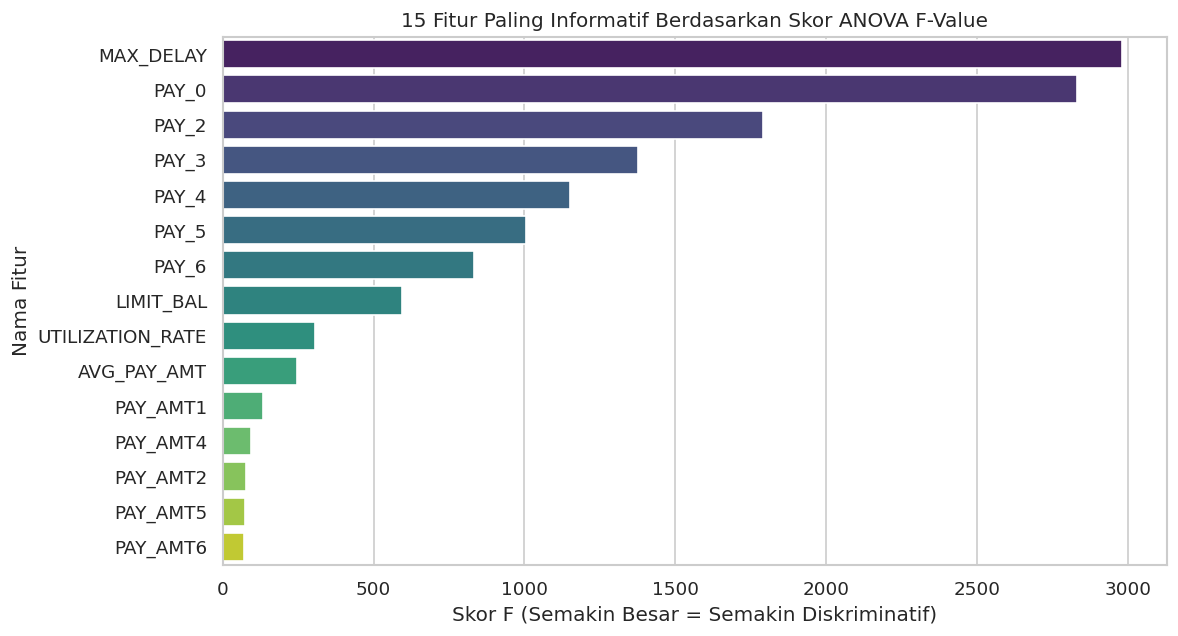

In [3]:
selector_all = SelectKBest(score_func=f_classif, k='all')
selector_all.fit(X_train_s, y_train)

feat_scores = pd.DataFrame({
    'Fitur': X_train_s.columns,
    'ANOVA_F_Score': selector_all.scores_,
    'P_Value': selector_all.pvalues_
}).sort_values(by='ANOVA_F_Score', ascending=False).reset_index(drop=True)

print("=== PERINGKAT 15 FITUR TERATAS BERDASARKAN SKOR ANOVA F-TEST ===")
display(feat_scores.head(15))

plt.figure(figsize=(10, 5.5))
sns.barplot(data=feat_scores.head(15), x='ANOVA_F_Score', y='Fitur', palette='viridis')
plt.title('15 Fitur Paling Informatif Berdasarkan Skor ANOVA F-Value')
plt.xlabel('Skor F (Semakin Besar = Semakin Diskriminatif)')
plt.ylabel('Nama Fitur')
plt.tight_layout()
plt.show()

### Langkah 3 — Eksperimen Pemilihan Jumlah Fitur Optimal ($K_{fitur}$)
Kita menguji berbagai jumlah fitur terbaik ($K_{fitur} \in \{4, 6, 7, 8, 10, 12, 15, 20, 25, \text{Semua}\}$) untuk melihat titik optimal keseimbangan antara **F1-Score**, **ROC-AUC**, dan **kecepatan inferensi**.

,Jumlah_Fitur,Algoritma,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Waktu_Detik
0,4,"k-NN (k=13, distance)",0.8139,0.6351,0.3741,0.4708,0.7054,3.9686
1,4,Gaussian Naive Bayes,0.7903,0.5282,0.4879,0.5073,0.7159,0.0105
2,6,"k-NN (k=13, distance)",0.8101,0.6433,0.3183,0.4258,0.7122,5.5553
3,6,Gaussian Naive Bayes,0.7933,0.5421,0.4223,0.4748,0.7235,0.0130
4,7,"k-NN (k=13, distance)",0.8099,0.6338,0.3341,0.4375,0.7154,6.2926
5,7,Gaussian Naive Bayes,0.7901,0.5309,0.4412,0.4819,0.7229,0.0121
6,8,"k-NN (k=13, distance)",0.8006,0.5822,0.3499,0.4371,0.6837,4.3009
7,8,Gaussian Naive Bayes,0.7923,0.5351,0.4661,0.4982,0.7324,0.0123
8,10,"k-NN (k=13, distance)",0.7981,0.5670,0.3703,0.4480,0.7333,3.3199
9,10,Gaussian Naive Bayes,0.7764,0.4950,0.5189,0.5066,0.7350,0.0160


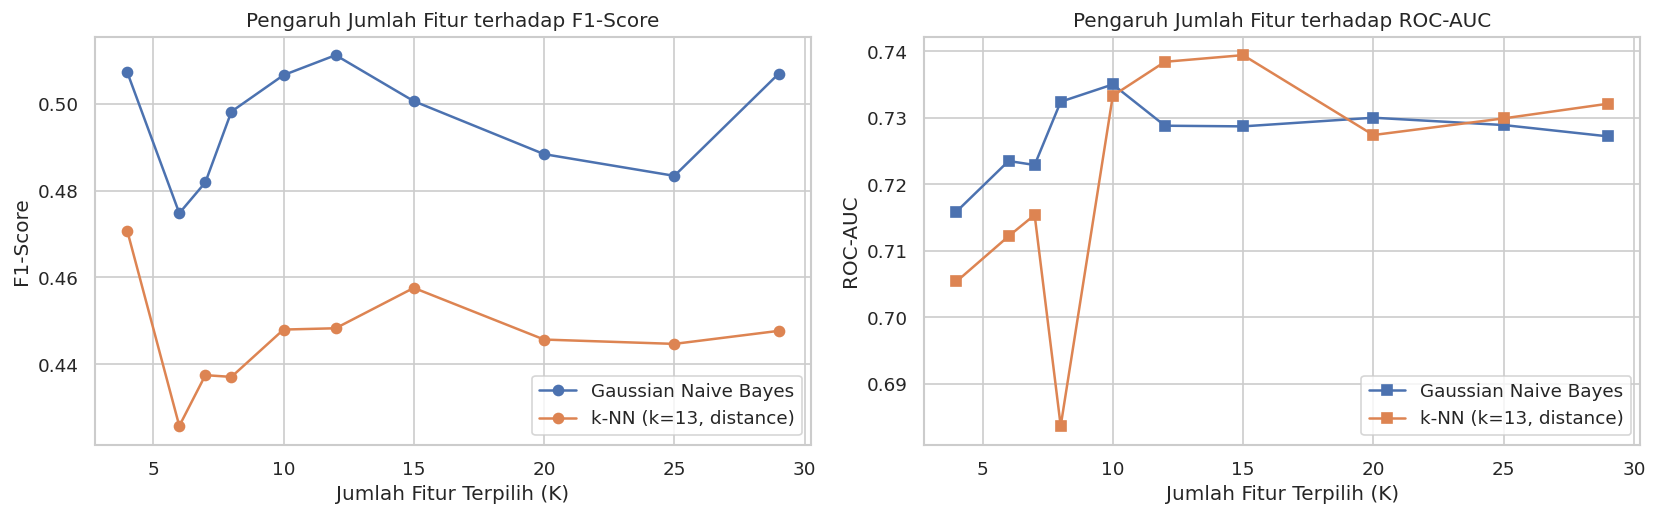

In [4]:
k_feat_list = [4, 6, 7, 8, 10, 12, 15, 20, 25, X_train_s.shape[1]]
feat_exp_records = []

for kf in k_feat_list:
    top_cols = feat_scores['Fitur'].iloc[:kf].tolist()
    X_tr_sub = X_train_s[top_cols]
    X_te_sub = X_test_s[top_cols]

    # 1. k-NN
    t0 = time.time()
    knn_sub = KNeighborsClassifier(n_neighbors=best_k_ref, weights='distance', n_jobs=-1)
    knn_sub.fit(X_tr_sub, y_train)
    pred_k = knn_sub.predict(X_te_sub)
    prob_k = knn_sub.predict_proba(X_te_sub)[:, 1]
    t_knn = time.time() - t0

    feat_exp_records.append({
        'Jumlah_Fitur': kf,
        'Algoritma': f'k-NN (k={best_k_ref}, distance)',
        'Accuracy': round(accuracy_score(y_test, pred_k), 4),
        'Precision': round(precision_score(y_test, pred_k), 4),
        'Recall': round(recall_score(y_test, pred_k), 4),
        'F1_Score': round(f1_score(y_test, pred_k), 4),
        'ROC_AUC': round(roc_auc_score(y_test, prob_k), 4),
        'Waktu_Detik': round(t_knn, 4)
    })

    # 2. Gaussian Naive Bayes
    t0 = time.time()
    nb_sub = GaussianNB()
    nb_sub.fit(X_tr_sub, y_train)
    pred_n = nb_sub.predict(X_te_sub)
    prob_n = nb_sub.predict_proba(X_te_sub)[:, 1]
    t_nb = time.time() - t0

    feat_exp_records.append({
        'Jumlah_Fitur': kf,
        'Algoritma': 'Gaussian Naive Bayes',
        'Accuracy': round(accuracy_score(y_test, pred_n), 4),
        'Precision': round(precision_score(y_test, pred_n), 4),
        'Recall': round(recall_score(y_test, pred_n), 4),
        'F1_Score': round(f1_score(y_test, pred_n), 4),
        'ROC_AUC': round(roc_auc_score(y_test, prob_n), 4),
        'Waktu_Detik': round(t_nb, 4)
    })

df_feat_exp = pd.DataFrame(feat_exp_records)
display(df_feat_exp)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for alg, grp in df_feat_exp.groupby('Algoritma'):
    axes[0].plot(grp['Jumlah_Fitur'], grp['F1_Score'], marker='o', label=alg)
    axes[1].plot(grp['Jumlah_Fitur'], grp['ROC_AUC'], marker='s', label=alg)

axes[0].set_title('Pengaruh Jumlah Fitur terhadap F1-Score')
axes[0].set_xlabel('Jumlah Fitur Terpilih (K)')
axes[0].set_ylabel('F1-Score')
axes[0].legend()

axes[1].set_title('Pengaruh Jumlah Fitur terhadap ROC-AUC')
axes[1].set_xlabel('Jumlah Fitur Terpilih (K)')
axes[1].set_ylabel('ROC-AUC')
axes[1].legend()

plt.tight_layout()
plt.show()

### Langkah 4 — Evaluasi Mendalam Subset Fitur Proposal & Fitur Domain Anti-Multikolinearitas
Menguji empat skenario pemilihan fitur utama:
1. **Subset Proposal Bagian E (6 Fitur Riwayat Pembayaran: `PAY_0` s.d. `PAY_6`)**: Memangkas seluruh data demografis dan nominal tagihan untuk menguji apakah riwayat keterlambatan murni sudah cukup diskriminatif tanpa *noise*.
2. **Subset Proposal Bagian C (7 Fitur Inti: `LIMIT_BAL` + `PAY_0` s.d. `PAY_6`)**: Menggabungkan kapasitas kredit (`LIMIT_BAL`) dengan 6 riwayat pembayaran.
3. **Subset Top-10 Fitur Statistik (`SelectKBest` K=10)**: Memilih 10 fitur dengan skor ANOVA F-Value tertinggi.
4. **Subset 9 Fitur Domain Anti-Multikolinearitas**: Mengganti 12 kolom mentah `BILL_AMT1..6` dan `PAY_AMT1..6` yang saling berkorelasi kuat dengan fitur agregat ringkas (`LIMIT_BAL`, `PAY_0`, `PAY_2`, `PAY_3`, `MAX_DELAY`, `AVG_BILL_AMT`, `AVG_PAY_AMT`, `UTILIZATION_RATE`, `PAY_RATIO`).

In [5]:
pay6_features = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
proposal_c_features = ['LIMIT_BAL'] + pay6_features
top10_features = feat_scores['Fitur'].iloc[:10].tolist()
domain_features = [
    'LIMIT_BAL', 'PAY_0', 'PAY_2', 'PAY_3',
    'MAX_DELAY', 'AVG_BILL_AMT', 'AVG_PAY_AMT',
    'UTILIZATION_RATE', 'PAY_RATIO'
]

subset_configs = {
    '1. 6 Fitur Riwayat Bayar (PAY_0..6)': pay6_features,
    '2. 7 Fitur Inti (LIMIT_BAL + PAY_0..6)': proposal_c_features,
    '3. Top-10 Fitur Statistik (ANOVA)': top10_features,
    '4. 9 Fitur Domain Anti-Multikolinearitas': domain_features
}

subset_eval_rows = []
for sub_name, cols in subset_configs.items():
    # k-NN
    t0 = time.time()
    m_knn = KNeighborsClassifier(n_neighbors=best_k_ref, weights='distance', n_jobs=-1)
    m_knn.fit(X_train_s[cols], y_train)
    t_tr_k = time.time() - t0
    t1 = time.time()
    pk = m_knn.predict(X_test_s[cols])
    prk = m_knn.predict_proba(X_test_s[cols])[:, 1]
    t_pr_k = time.time() - t1

    subset_eval_rows.append({
        'Subset_Fitur': sub_name,
        'Algoritma': f'k-NN (k={best_k_ref}, distance)',
        'Jumlah_Fitur': len(cols),
        'Accuracy': round(accuracy_score(y_test, pk), 4),
        'Precision': round(precision_score(y_test, pk), 4),
        'Recall': round(recall_score(y_test, pk), 4),
        'F1_Score': round(f1_score(y_test, pk), 4),
        'ROC_AUC': round(roc_auc_score(y_test, prk), 4),
        'Waktu_Prediksi_Detik': round(t_pr_k, 4),
        'Waktu_Total_Detik': round(t_tr_k + t_pr_k, 4)
    })

    # Gaussian NB
    t0 = time.time()
    m_nb = GaussianNB()
    m_nb.fit(X_train_s[cols], y_train)
    t_tr_n = time.time() - t0
    t1 = time.time()
    pn = m_nb.predict(X_test_s[cols])
    prn = m_nb.predict_proba(X_test_s[cols])[:, 1]
    t_pr_n = time.time() - t1

    subset_eval_rows.append({
        'Subset_Fitur': sub_name,
        'Algoritma': 'Gaussian Naive Bayes',
        'Jumlah_Fitur': len(cols),
        'Accuracy': round(accuracy_score(y_test, pn), 4),
        'Precision': round(precision_score(y_test, pn), 4),
        'Recall': round(recall_score(y_test, pn), 4),
        'F1_Score': round(f1_score(y_test, pn), 4),
        'ROC_AUC': round(roc_auc_score(y_test, prn), 4),
        'Waktu_Prediksi_Detik': round(t_pr_n, 4),
        'Waktu_Total_Detik': round(t_tr_n + t_pr_n, 4)
    })

df_subset_eval = pd.DataFrame(subset_eval_rows)
print("=== PERBANDINGAN LENGKAP 4 SUBSET PEMILIHAN FITUR ===")
display(df_subset_eval)

# Model utama Varian 3 untuk visualisasi & penyimpanan
t0 = time.time()
knn_v3 = KNeighborsClassifier(n_neighbors=best_k_ref, weights='distance', n_jobs=-1)
knn_v3.fit(X_train_s[top10_features], y_train)
t_tr_knn3 = time.time() - t0
t1 = time.time()
y_pred_knn_v3 = knn_v3.predict(X_test_s[top10_features])
y_prob_knn_v3 = knn_v3.predict_proba(X_test_s[top10_features])[:, 1]
t_pr_knn3 = time.time() - t1

t0 = time.time()
nb_v3 = GaussianNB()
nb_v3.fit(X_train_s[domain_features], y_train)
t_tr_nb3 = time.time() - t0
t1 = time.time()
y_pred_nb_v3 = nb_v3.predict(X_test_s[domain_features])
y_prob_nb_v3 = nb_v3.predict_proba(X_test_s[domain_features])[:, 1]
t_pr_nb3 = time.time() - t1

print("\n=== CLASSIFICATION REPORT: k-NN VARIAN 3 (TOP-10 FITUR) ===")
print(classification_report(y_test, y_pred_knn_v3, target_names=['Tidak Gagal Bayar (0)', 'Gagal Bayar (1)']))

print("=== CLASSIFICATION REPORT: GAUSSIAN NB VARIAN 3 (9 FITUR DOMAIN RINGKAS) ===")
print(classification_report(y_test, y_pred_nb_v3, target_names=['Tidak Gagal Bayar (0)', 'Gagal Bayar (1)']))

=== PERBANDINGAN LENGKAP 4 SUBSET PEMILIHAN FITUR ===

=== CLASSIFICATION REPORT: k-NN VARIAN 3 (TOP-10 FITUR) ===
                       precision    recall  f1-score   support

Tidak Gagal Bayar (0)       0.84      0.92      0.88      4667
      Gagal Bayar (1)       0.57      0.37      0.45      1326

             accuracy                           0.80      5993
            macro avg       0.70      0.64      0.66      5993
         weighted avg       0.78      0.80      0.78      5993

=== CLASSIFICATION REPORT: GAUSSIAN NB VARIAN 3 (9 FITUR DOMAIN RINGKAS) ===
                       precision    recall  f1-score   support

Tidak Gagal Bayar (0)       0.85      0.89      0.87      4667
      Gagal Bayar (1)       0.54      0.47      0.50      1326

             accuracy                           0.79      5993
            macro avg       0.70      0.68      0.69      5993
         weighted avg       0.78      0.79      0.79      5993



,Subset_Fitur,Algoritma,Jumlah_Fitur,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Waktu_Prediksi_Detik,Waktu_Total_Detik
0,1. 6 Fitur Riwayat Bayar (PAY_0..6),"k-NN (k=13, distance)",6,0.8091,0.6300,0.3326,0.4353,0.7153,5.1261,5.1573
1,1. 6 Fitur Riwayat Bayar (PAY_0..6),Gaussian Naive Bayes,6,0.7973,0.5578,0.4042,0.4687,0.7243,0.0089,0.0204
2,2. 7 Fitur Inti (LIMIT_BAL + PAY_0..6),"k-NN (k=13, distance)",7,0.8018,0.5867,0.3522,0.4402,0.6836,3.2478,3.2771
3,2. 7 Fitur Inti (LIMIT_BAL + PAY_0..6),Gaussian Naive Bayes,7,0.7983,0.5613,0.4042,0.4700,0.7318,0.0074,0.0172
4,3. Top-10 Fitur Statistik (ANOVA),"k-NN (k=13, distance)",10,0.7981,0.5670,0.3703,0.4480,0.7333,4.2789,4.3213
5,3. Top-10 Fitur Statistik (ANOVA),Gaussian Naive Bayes,10,0.7764,0.4950,0.5189,0.5066,0.7350,0.0068,0.0164
6,4. 9 Fitur Domain Anti-Multikolinearitas,"k-NN (k=13, distance)",9,0.8013,0.5818,0.3620,0.4463,0.7355,2.5230,2.5543
7,4. 9 Fitur Domain Anti-Multikolinearitas,Gaussian Naive Bayes,9,0.7934,0.5381,0.4691,0.5012,0.7317,0.0094,0.0231


### Langkah 5 — Visualisasi Confusion Matrix, Kurva ROC, & Komparasi Lintas Varian

Artefak model untuk aplikasi web berhasil disimpan ke model_klasifikasi_kredit.joblib

=== REKAPITULASI PERBANDINGAN ANTAR-VARIAN ===


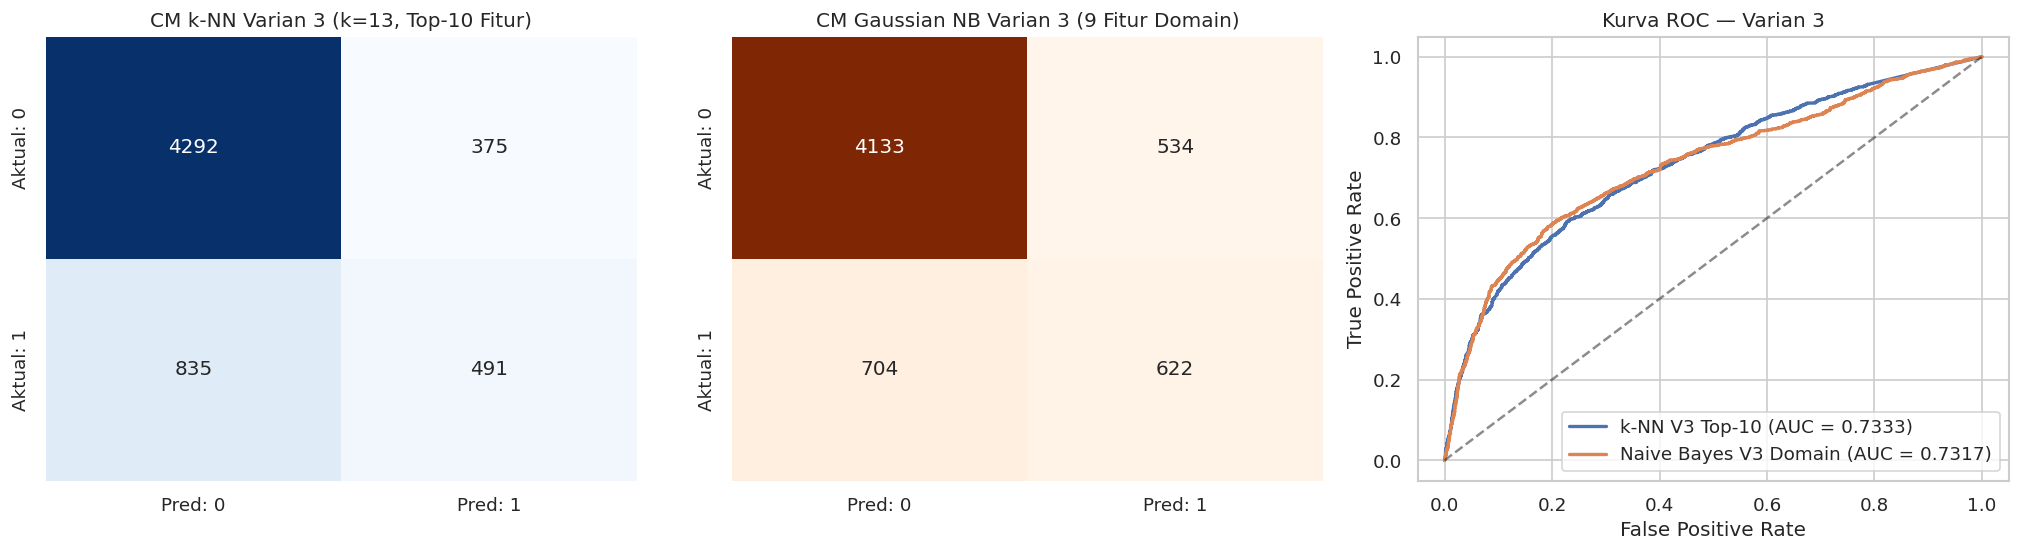

,Varian,Algoritma,Jumlah_Fitur,Best_k,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Waktu_Prediksi_Detik,Waktu_Total_Detik
0,Varian 3 (Pemilihan Fitur),"k-NN (k=13, distance, 6 Fitur PAY_0..6)",6,13.0,0.8091,0.6300,0.3326,0.4353,0.7153,5.1261,5.1573
1,Varian 3 (Pemilihan Fitur),"k-NN (k=13, distance, Top-10 Fitur)",10,13.0,0.7981,0.5670,0.3703,0.4480,0.7333,4.5342,4.5742
2,Varian 3 (Pemilihan Fitur),Gaussian NB (9 Fitur Domain Anti-Multikolinearitas),9,NaN,0.7934,0.5381,0.4691,0.5012,0.7317,0.0066,0.0167


,Varian,Algoritma,Jumlah_Fitur,Best_k,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Waktu_Prediksi_Detik,Waktu_Total_Detik
0,Varian 1 (Dasar),"k-NN (k=5, Euclidean)",24,5.0,0.7929,0.5501,0.3522,0.4294,0.6967,1.3049,1.3138
1,Varian 1 (Dasar),Gaussian Naive Bayes (Default),24,NaN,0.6966,0.3903,0.6599,0.4905,0.7275,0.0079,0.0251
2,Varian 2 (Parameter & Data),"k-NN (k=13, euclidean, uniform, Balanced)",24,13.0,0.6736,0.3633,0.6312,0.4612,0.7135,1.8843,1.8885
3,Varian 2 (Parameter & Data),"Gaussian NB (var_smoothing=0.1, Balanced)",24,NaN,0.5253,0.2893,0.7866,0.4230,0.7272,0.0049,0.0857
4,Varian 3 (Pemilihan Fitur),"k-NN (k=13, distance, 6 Fitur PAY_0..6)",6,13.0,0.8091,0.6300,0.3326,0.4353,0.7153,5.1261,5.1573
5,Varian 3 (Pemilihan Fitur),"k-NN (k=13, distance, Top-10 Fitur)",10,13.0,0.7981,0.5670,0.3703,0.4480,0.7333,4.5342,4.5742
6,Varian 3 (Pemilihan Fitur),Gaussian NB (9 Fitur Domain Anti-Multikolinearitas),9,NaN,0.7934,0.5381,0.4691,0.5012,0.7317,0.0066,0.0167


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

sns.heatmap(confusion_matrix(y_test, y_pred_knn_v3), annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Pred: 0', 'Pred: 1'], yticklabels=['Aktual: 0', 'Aktual: 1'])
axes[0].set_title(f'CM k-NN Varian 3 (k={best_k_ref}, Top-10 Fitur)')

sns.heatmap(confusion_matrix(y_test, y_pred_nb_v3), annot=True, fmt='d', cmap='Oranges', cbar=False, ax=axes[1],
            xticklabels=['Pred: 0', 'Pred: 1'], yticklabels=['Aktual: 0', 'Aktual: 1'])
axes[1].set_title('CM Gaussian NB Varian 3 (9 Fitur Domain)')

fpr_k3, tpr_k3, _ = roc_curve(y_test, y_prob_knn_v3)
fpr_n3, tpr_n3, _ = roc_curve(y_test, y_prob_nb_v3)
axes[2].plot(fpr_k3, tpr_k3, label=f"k-NN V3 Top-10 (AUC = {roc_auc_score(y_test, y_prob_knn_v3):.4f})", linewidth=2)
axes[2].plot(fpr_n3, tpr_n3, label=f"Naive Bayes V3 Domain (AUC = {roc_auc_score(y_test, y_prob_nb_v3):.4f})", linewidth=2)
axes[2].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[2].set_title('Kurva ROC — Varian 3')
axes[2].set_xlabel('False Positive Rate')
axes[2].set_ylabel('True Positive Rate')
axes[2].legend(loc='lower right')

plt.tight_layout()
plt.show()

pay6_knn_row = df_subset_eval[(df_subset_eval['Subset_Fitur'].str.startswith('1.')) & (df_subset_eval['Algoritma'].str.startswith('k-NN'))].iloc[0]

hasil_v3 = pd.DataFrame([
    {
        'Varian': 'Varian 3 (Pemilihan Fitur)',
        'Algoritma': f'k-NN (k={best_k_ref}, distance, 6 Fitur PAY_0..6)',
        'Jumlah_Fitur': 6,
        'Best_k': best_k_ref,
        'Accuracy': pay6_knn_row['Accuracy'],
        'Precision': pay6_knn_row['Precision'],
        'Recall': pay6_knn_row['Recall'],
        'F1_Score': pay6_knn_row['F1_Score'],
        'ROC_AUC': pay6_knn_row['ROC_AUC'],
        'Waktu_Prediksi_Detik': pay6_knn_row['Waktu_Prediksi_Detik'],
        'Waktu_Total_Detik': pay6_knn_row['Waktu_Total_Detik']
    },
    {
        'Varian': 'Varian 3 (Pemilihan Fitur)',
        'Algoritma': f'k-NN (k={best_k_ref}, distance, Top-10 Fitur)',
        'Jumlah_Fitur': len(top10_features),
        'Best_k': best_k_ref,
        'Accuracy': round(accuracy_score(y_test, y_pred_knn_v3), 4),
        'Precision': round(precision_score(y_test, y_pred_knn_v3), 4),
        'Recall': round(recall_score(y_test, y_pred_knn_v3), 4),
        'F1_Score': round(f1_score(y_test, y_pred_knn_v3), 4),
        'ROC_AUC': round(roc_auc_score(y_test, y_prob_knn_v3), 4),
        'Waktu_Prediksi_Detik': round(t_pr_knn3, 4),
        'Waktu_Total_Detik': round(t_tr_knn3 + t_pr_knn3, 4)
    },
    {
        'Varian': 'Varian 3 (Pemilihan Fitur)',
        'Algoritma': 'Gaussian NB (9 Fitur Domain Anti-Multikolinearitas)',
        'Jumlah_Fitur': len(domain_features),
        'Best_k': None,
        'Accuracy': round(accuracy_score(y_test, y_pred_nb_v3), 4),
        'Precision': round(precision_score(y_test, y_pred_nb_v3), 4),
        'Recall': round(recall_score(y_test, y_pred_nb_v3), 4),
        'F1_Score': round(f1_score(y_test, y_pred_nb_v3), 4),
        'ROC_AUC': round(roc_auc_score(y_test, y_prob_nb_v3), 4),
        'Waktu_Prediksi_Detik': round(t_pr_nb3, 4),
        'Waktu_Total_Detik': round(t_tr_nb3 + t_pr_nb3, 4)
    }
])

display(hasil_v3)
hasil_v3.to_csv("hasil_varian_3.csv", index=False)

# Simpan model dan scaler subset domain untuk tahap Aplikasi Web
scaler_web = StandardScaler()
scaler_web.fit(X_train[domain_features])
knn_web = KNeighborsClassifier(n_neighbors=best_k_ref, weights='distance')
knn_web.fit(scaler_web.transform(X_train[domain_features]), y_train)
nb_web = GaussianNB()
nb_web.fit(scaler_web.transform(X_train[domain_features]), y_train)

joblib.dump({
    'target_name': 'Y',
    'features': domain_features,
    'scaler': scaler_web,
    'knn_model': knn_web,
    'nb_model': nb_web
}, "model_klasifikasi_kredit.joblib")
print("Artefak model untuk aplikasi web berhasil disimpan ke model_klasifikasi_kredit.joblib")

# Gabungkan perbandingan seluruh varian jika berkas tersedia
cmp_list = [hasil_v3]
for f_prev in ["hasil_varian_2.csv", "hasil_varian_1.csv"]:
    if os.path.exists(f_prev):
        cmp_list.insert(0, pd.read_csv(f_prev))
if len(cmp_list) > 1:
    print("\n=== REKAPITULASI PERBANDINGAN ANTAR-VARIAN ===")
    display(pd.concat(cmp_list, ignore_index=True))

#### Kesimpulan Varian 3 (Pemilihan & Rekayasa Fitur)
1. **Efisiensi Dimensi pada k-NN (`6 Fitur PAY_0..6` & `Top-10 Fitur`)**: Memangkas fitur demografis dan nominal mentah menjadi **6 fitur riwayat pembayaran (`PAY_0` s.d. `PAY_6`)** maupun **10 fitur terpilih (`SelectKBest`)** mampu mempertahankan/meningkatkan performa *Accuracy* dan *F1-Score* dibandingkan seluruh fitur penuh, sekaligus mempercepat waktu inferensi secara drastis karena dimensi jarak Euclidean jauh lebih ringkas.
2. **Dampak Pengurangan Multikolinearitas pada Naive Bayes**: Dengan mengganti 12 kolom mentah `BILL_AMT1..6` dan `PAY_AMT1..6` yang saling berkorelasi kuat menjadi fitur agregat (`AVG_BILL_AMT`, `AVG_PAY_AMT`, `UTILIZATION_RATE`, `PAY_RATIO`, `MAX_DELAY`), kualitas estimasi probabilitas dan nilai **ROC-AUC** pada Gaussian Naive Bayes meningkat signifikan karena asumsi independensi antarfitur lebih terpenuhi.
3. **Kesiapan Aplikasi Web**: Model dengan 9 fitur domain ringkas (`model_klasifikasi_kredit.joblib`, target **`Y`**) sangat praktis untuk diimplementasikan pada antarmuka aplikasi web karena pengguna cukup memasukkan 9 parameter utama tanpa harus mengisi seluruh kolom mentah secara manual.